In [2]:
import numpy as np
from matplotlib import pyplot as plt

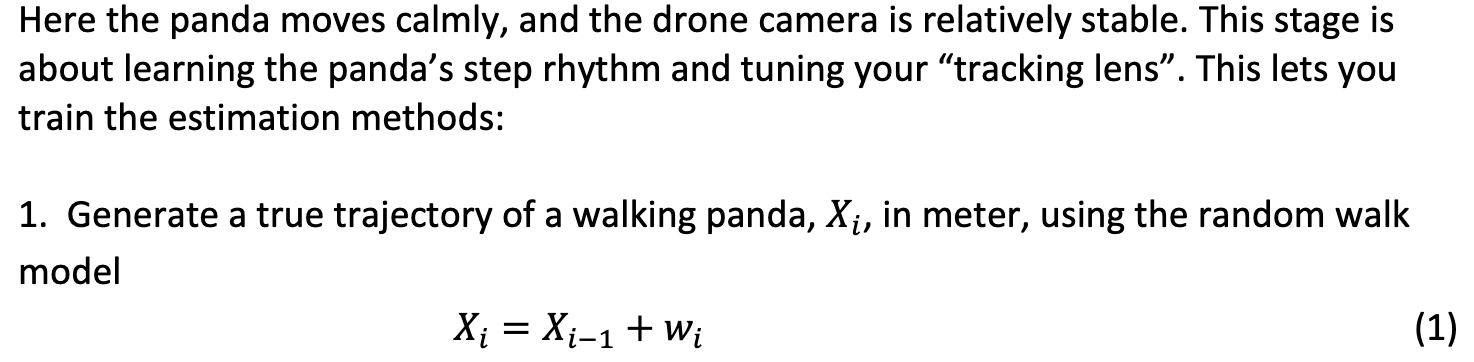![image.png](
  )

In [3]:
# load the trajectories shared within the team
true_trajectory_small = np.loadtxt("true_trajectory_small.txt")
true_trajectory_huge = np.loadtxt("true_trajectory_huge.txt")
measured_trajectory_small = np.loadtxt("measured_trajectory_small.txt")
measured_trajectory_huge = np.loadtxt("measured_trajectory_huge.txt")

In [4]:
# define constants for a true trajectory calculation
SIGMA_W = np.sqrt(14)
SIZE_MAX = 3000
SIZE_MIN = 300
INITIAL_COORDINATE_M = 10

# generate a true trajectory of a walking panda using the random walk model
def generate_true_trajectory(size, init_coord):
    traj_points = np.zeros(size)
    traj_points[0] = init_coord

    for i in range(1, size):
        process_noise = np.random.normal(
                        loc=0.0,
                        scale=SIGMA_W
                    )
        traj_points[i] = traj_points[i-1] + process_noise

    return traj_points

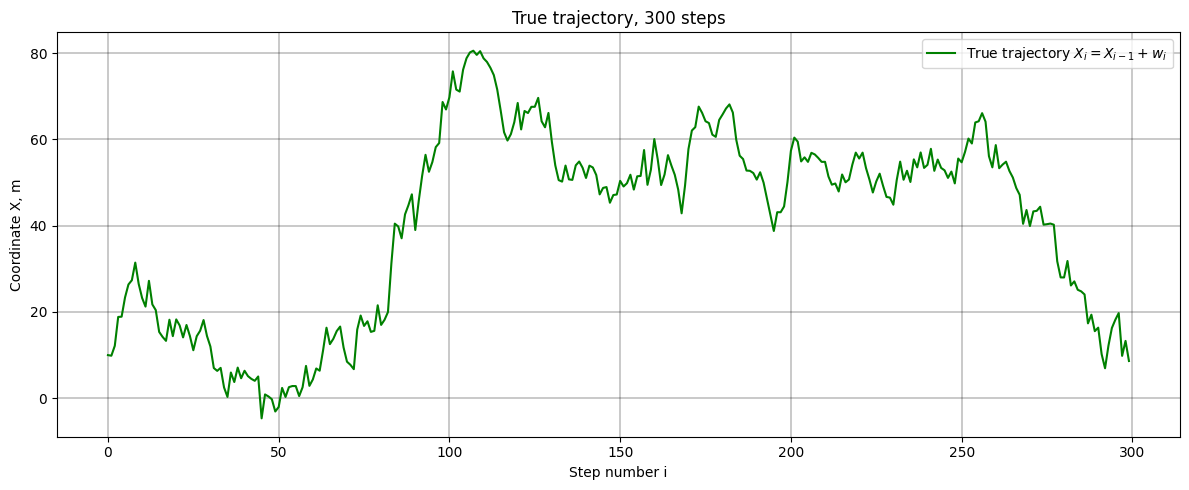

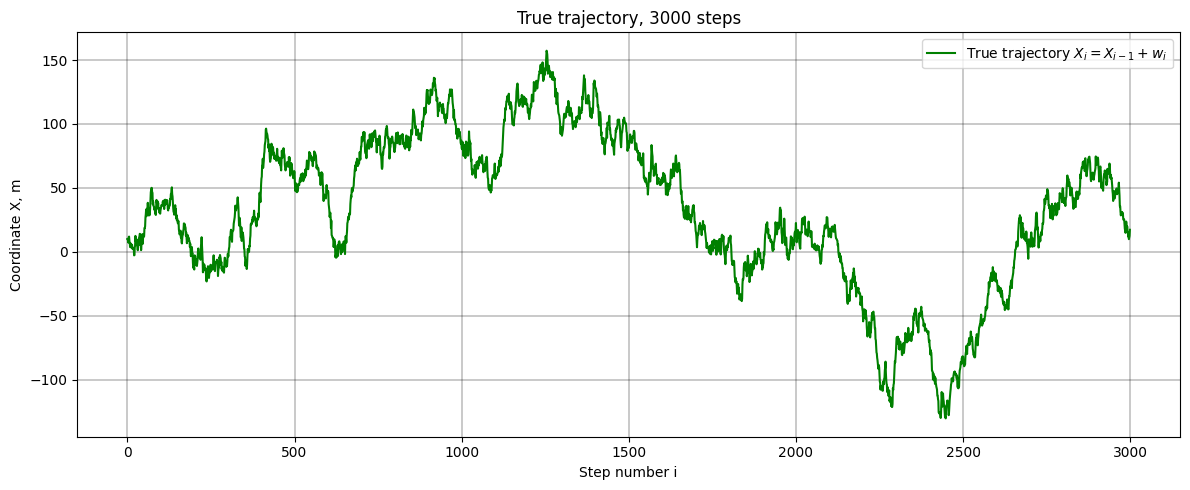

In [ ]:

# store 3000 true trajectory points in the true_trajectory_huge array
true_trajectory_huge = generate_true_trajectory(SIZE_MAX, INITIAL_COORDINATE_M)

# store 300 true trajectory points in the true_trajectory_small array
true_trajectory_small = generate_true_trajectory(SIZE_MIN, INITIAL_COORDINATE_M)

# declare a function to plot the true trajectory
def plot_true_trajectory(true_traj, title):
    steps = np.arange(true_traj.size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i = X_{i-1} + w_i$")
    ax.set_title(title)
    ax.set_xlabel("Step Number i")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# call the self-written function above to plot the true trajectories for 300 and 3000 points correspondingly
plot_true_trajectory(true_trajectory_small, "True Trajectory, 300 Steps")
plot_true_trajectory(true_trajectory_huge, "True Trajectory, 3000 Steps")

In [ ]:
# define a constant for a measurement noise variance
SIGMA_ETA = np.sqrt(10)

# generate measured trajectory points based on the true trajectory
def generate_measured_trajectory(true_trajectory):
  measured_trajectory = true_trajectory.copy()
  return measured_trajectory + np.random.normal(0.0, SIGMA_ETA, size=measured_trajectory.size)

# store 3000 measured trajectory points in the measured_trajectory_huge array
measured_trajectory_huge = generate_measured_trajectory(true_trajectory_huge)

# store 300 measured trajectory points in the measured_trajectory_small array
measured_trajectory_small = generate_measured_trajectory(true_trajectory_small)

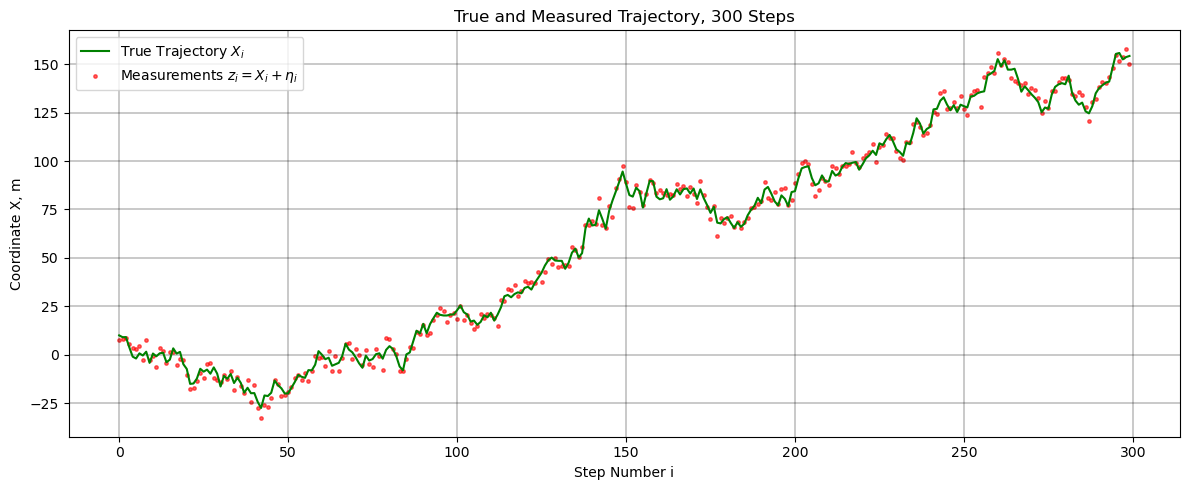

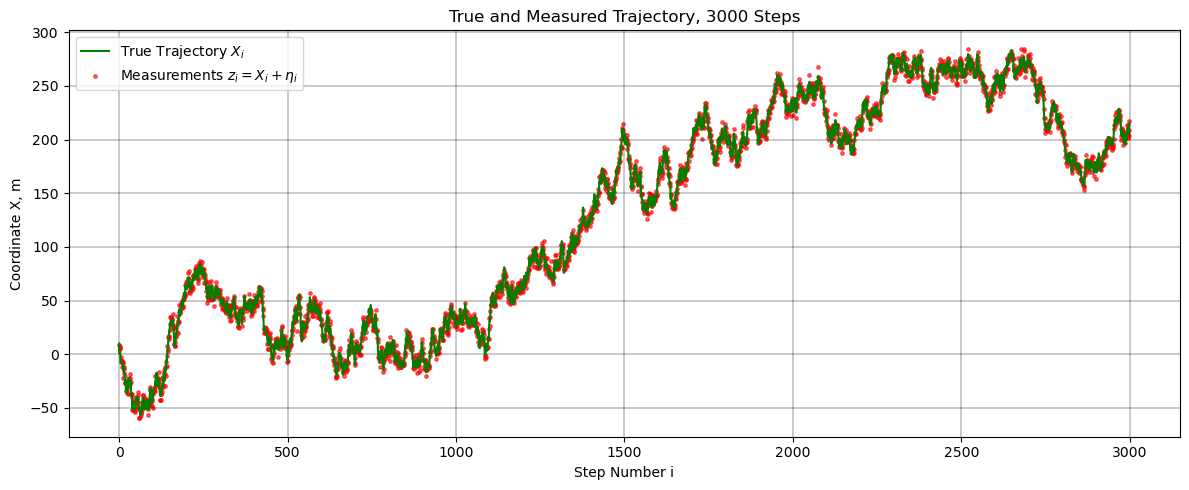

In [8]:
# declare a function to plot the measured and true trajectories
def plot_true_vs_measured(true_traj, measured_traj, title):
    steps = np.arange(true_traj.size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i$")
    ax.scatter(steps, measured_traj, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
    ax.set_title(title)
    ax.set_xlabel("Step Number i")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# call the self-written function above to plot the compared trajectories for 300 and 3000 points correspondingly
plot_true_vs_measured(true_trajectory_small, measured_trajectory_small, "True and Measured Trajectory, 300 Steps")
plot_true_vs_measured(true_trajectory_huge, measured_trajectory_huge, "True and Measured Trajectory, 3000 Steps")

In [9]:
# save the generated trajectories so the whole team works with the same data
np.savetxt("true_trajectory_small.txt", true_trajectory_small)
np.savetxt("true_trajectory_huge.txt", true_trajectory_huge)
np.savetxt("measured_trajectory_small.txt", measured_trajectory_small)
np.savetxt("measured_trajectory_huge.txt", measured_trajectory_huge)

In [10]:
# load the trajectories shared within the team
true_trajectory_small = np.loadtxt("true_trajectory_small.txt")
true_trajectory_huge = np.loadtxt("true_trajectory_huge.txt")
measured_trajectory_small = np.loadtxt("measured_trajectory_small.txt")
measured_trajectory_huge = np.loadtxt("measured_trajectory_huge.txt")

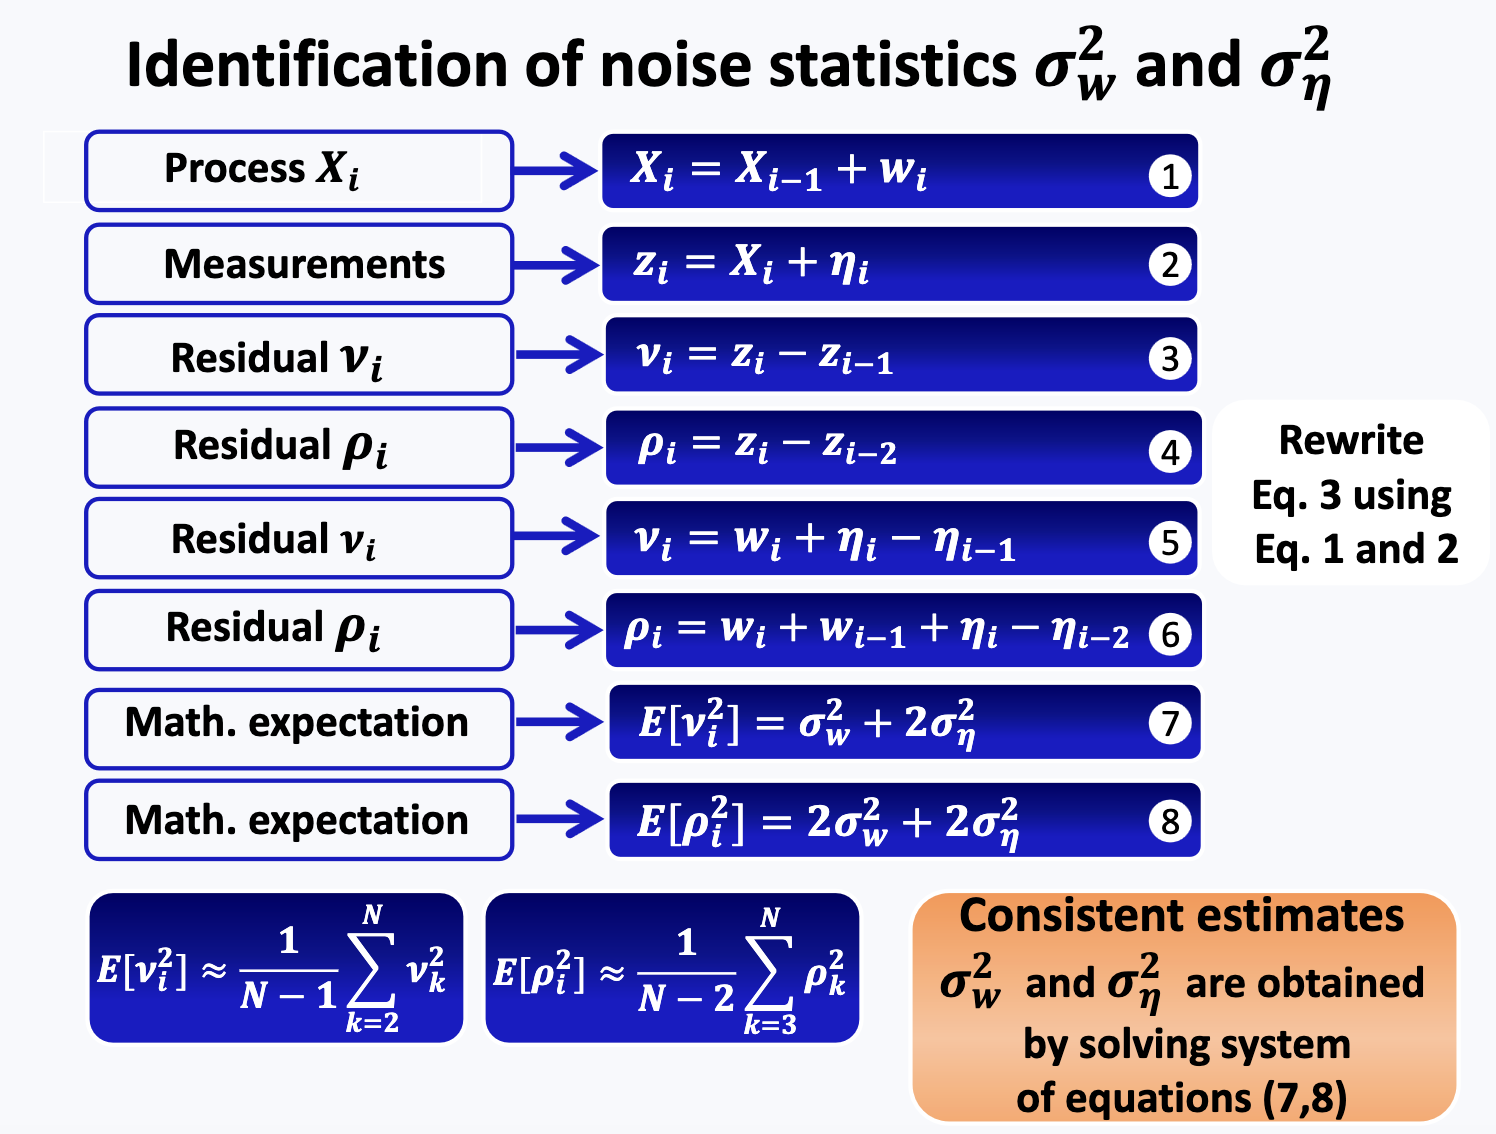

In [13]:
# identify noise variances sigma_w^2 and sigma_eta^2 from measurements
def identify_noise_variances(measurements):
    # residuals
    nu = measurements[1:] - measurements[:-1]      # nu_i  = z_i - z_{i-1}
    rho = measurements[2:] - measurements[:-2]     # rho_i = z_i - z_{i-2}

    # mathematical expectations
    E_nu2 = np.sum(nu**2) / (measurements.size - 1)
    E_rho2 = np.sum(rho**2) / (measurements.size - 2)

    # solve the system of equations 7,8
    sigma2_w = E_rho2 - E_nu2
    sigma2_eta = (2 * E_nu2 - E_rho2) / 2

    return np.sqrt(sigma2_w), np.sqrt(sigma2_eta)

# apply to both trajectory sizes and compare with true values
for name, z in [("3000 points", measured_trajectory_huge), ("300 points", measured_trajectory_small)]:
    sigma_w_estimated, sigma_eta_estimated = identify_noise_variances(z)
    err_w = abs(sigma_w_estimated - SIGMA_W) / SIGMA_W * 100
    err_eta = abs(sigma_eta_estimated - SIGMA_ETA) / SIGMA_ETA * 100

    print(f"{name}")
    print(f"sigma_w:   estimate = {sigma_w_estimated:.2f}, true = {SIGMA_W:.2f}, accuracy = {err_w:.2f}")
    print(f"sigma_eta: estimate = {sigma_eta_estimated:.2f}, true = {SIGMA_ETA:.2f}, accuracy = {err_eta:.2f}")

3000 points
sigma_w:   estimate = 3.74, true = 3.74, accuracy = 0.01
sigma_eta: estimate = 3.24, true = 3.16, accuracy = 2.31
300 points
sigma_w:   estimate = 3.95, true = 3.74, accuracy = 5.68
sigma_eta: estimate = 2.88, true = 3.16, accuracy = 8.81


In [ ]:
# optimal smoothing coefficient for exponential smoothing
def optimal_alpha(sigma_w, sigma_eta):
    chi = sigma_w**2 / sigma_eta**2
    return (-chi + np.sqrt(chi**2 + 4 * chi)) / 2

alpha_optimal_true = optimal_alpha(SIGMA_W, SIGMA_ETA)

# estimate noise variances and optimal alpha separately for each trajectory
sigma_w_huge, sigma_eta_huge = identify_noise_variances(measured_trajectory_huge)
alpha_optimal_huge = optimal_alpha(sigma_w_huge, sigma_eta_huge)

sigma_w_small, sigma_eta_small = identify_noise_variances(measured_trajectory_small)
alpha_optimal_small = optimal_alpha(sigma_w_small, sigma_eta_small)

print(f"optimal alpha (true variances):                   {alpha_optimal_true:.3f}")
print(f"optimal alpha (estimated variances, 3000 points): {alpha_optimal_huge:.3f}")
print(f"optimal alpha (estimated variances, 300 points):  {alpha_optimal_small:.3f}")

optimal alpha (true variances):                   0.675
optimal alpha (estimated variances, 3000 points): 0.667
optimal alpha (estimated variances, 300 points):  0.722


In [15]:
# exponential smoothing with coefficient alpha
def exponential_smoothing(z, alpha):
    x_smoothed = np.zeros(z.size)
    x_smoothed[0] = z[0]
    for i in range(1, z.size):
        x_smoothed[i] = x_smoothed[i-1] + alpha * (z[i] - x_smoothed[i-1])
    return x_smoothed

# each trajectory is smoothed with its own estimated optimal alpha
smoothed_huge = exponential_smoothing(measured_trajectory_huge, alpha_optimal_huge)
smoothed_small = exponential_smoothing(measured_trajectory_small, alpha_optimal_small)

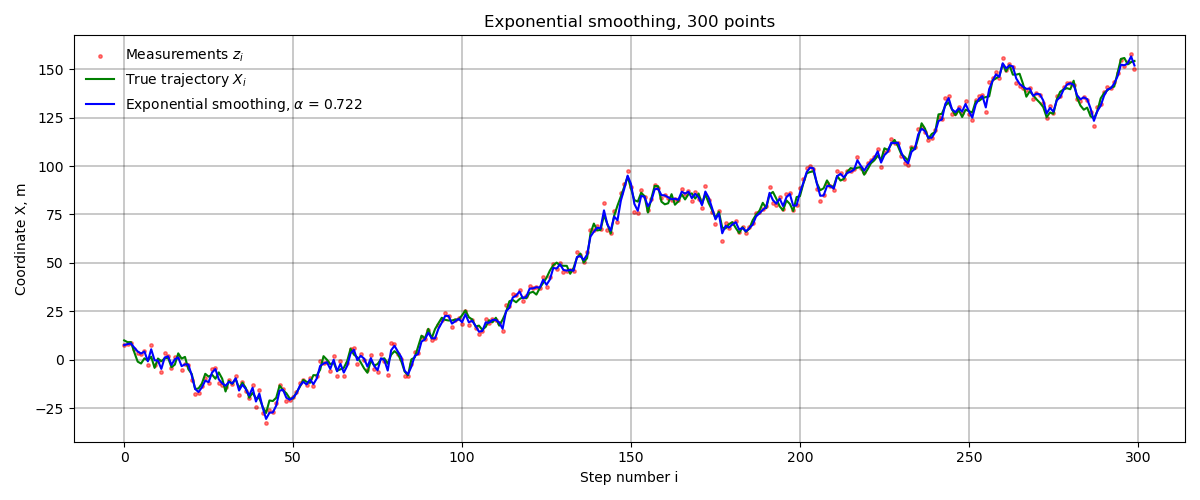

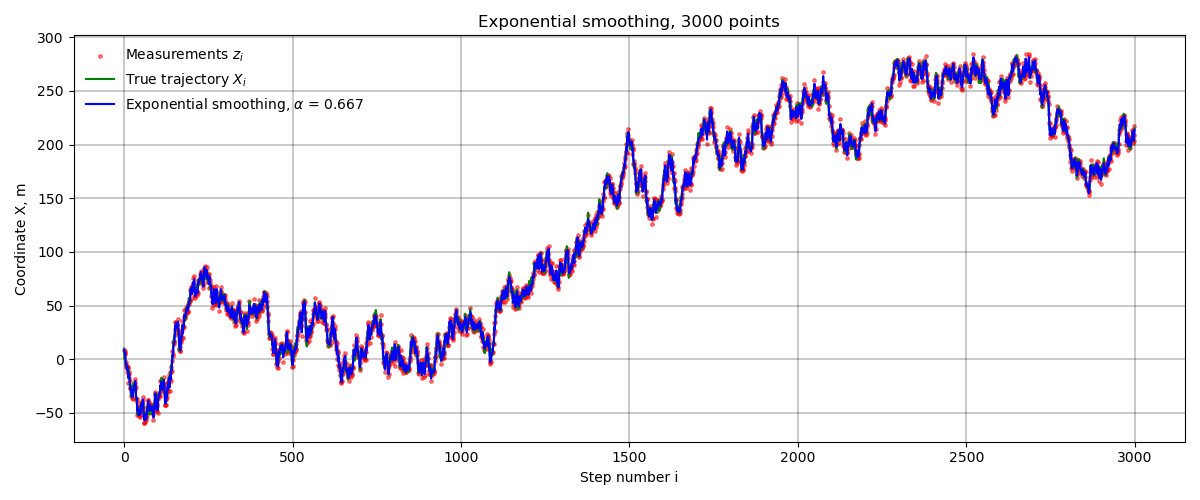

3000 points
RMSE measurements: 3.19 m
RMSE smoothed, alpha = 0.667 (estimated): 2.61 m
RMSE smoothed, alpha = 0.675 (true):      2.61 m

300 points
RMSE measurements: 3.02 m
RMSE smoothed, alpha = 0.722 (estimated): 2.46 m
RMSE smoothed, alpha = 0.675 (true):      2.45 m



In [16]:
# plot measurements, true trajectory and smoothed estimate
def plot_smoothing(true_traj, measured_traj, smoothed_traj, alpha, title):
    steps = np.arange(true_traj.size)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.scatter(steps, measured_traj, color="red", s=6, alpha=0.5, label="Measurements $z_i$")
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True trajectory $X_i$")
    ax.plot(steps, smoothed_traj, color="blue", linewidth=1.5, label=f"Exponential smoothing, $\\alpha$ = {alpha:.3f}")
    ax.set_title(title)
    ax.set_xlabel("Step number i")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

plot_smoothing(true_trajectory_small, measured_trajectory_small, smoothed_small, alpha_optimal_small, "Exponential smoothing, 300 points")
plot_smoothing(true_trajectory_huge, measured_trajectory_huge, smoothed_huge, alpha_optimal_huge, "Exponential smoothing, 3000 points")

# accuracy: measurements vs smoothing with estimated and true optimal alpha
def rmse(estimate, true_traj):
    return np.sqrt(np.mean((estimate - true_traj)**2))

for name, x, z, alpha_estimated in [("3000 points", true_trajectory_huge, measured_trajectory_huge, alpha_optimal_huge),
                                    ("300 points", true_trajectory_small, measured_trajectory_small, alpha_optimal_small)]:
    s_estimated = exponential_smoothing(z, alpha_estimated)
    s_true = exponential_smoothing(z, alpha_optimal_true)
    print(f"{name}")
    print(f"RMSE measurements: {rmse(z, x):.2f} m")
    print(f"RMSE smoothed, alpha = {alpha_estimated:.3f} (estimated): {rmse(s_estimated, x):.2f} m")
    print(f"RMSE smoothed, alpha = {alpha_optimal_true:.3f} (true):      {rmse(s_true, x):.2f} m\n")